
# PetBreed AI: Transfer Learning and Honest Generalisation Evaluation

### AI Engineering Internship — Practical Assignment

**Dataset:** Oxford-IIIT Pet (37 Cat and Dog Breeds)  
**Framework:** PyTorch and Torchvision  
**Models:** ResNet-18, EfficientNet-B0, MobileNetV3-Large  
**Selected Model:** EfficientNet-B0  
**Deployment:** Gradio  
**Development Environment:** Kaggle GPU

---

## Project Overview

This project develops and evaluates a multiclass image classifier
capable of identifying 37 cat and dog breeds.

Three ImageNet-pretrained architectures were fine-tuned and compared
using a consistent dataset split and validation procedure.

The best-performing model was selected using validation macro-F1,
then evaluated on the official Oxford-IIIT Pet test set and a
separate collection of web-sourced images.

The project emphasizes honest evaluation, reproducibility,
error analysis, and performance under distribution shift.


In [275]:

import torch
import torchvision
from torchvision.datasets import OxfordIIITPet

SEED = 42
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

trainval = OxfordIIITPet(
    root="/kaggle/working/data",
    split="trainval",
    target_types="category",
    download=True
)

test = OxfordIIITPet(
    root="/kaggle/working/data",
    split="test",
    target_types="category",
    download=True
)

print("Trainval samples:", len(trainval))
print("Test samples:", len(test))
print("Number of breeds:", len(trainval.classes))
  

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
Trainval samples: 3680
Test samples: 3669
Number of breeds: 37



## 1. Dataset Loading and Exploratory Analysis




In [276]:

import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# Retrieve the 37 breed names
class_names = trainval.classes

print("Total classes:", len(class_names))
print("\nBreed names:")

for index, breed in enumerate(class_names):
    print(f"{index:2d}: {breed}")

# Extract labels from the official training pool
labels = np.array([
    trainval[i][1] for i in range(len(trainval))
])

# Calculate how many images belong to each breed
class_counts = Counter(labels)

print("\nMinimum images per breed:",
      min(class_counts.values()))

print("Maximum images per breed:",
      max(class_counts.values()))


Total classes: 37

Breed names:
 0: Abyssinian
 1: American Bulldog
 2: American Pit Bull Terrier
 3: Basset Hound
 4: Beagle
 5: Bengal
 6: Birman
 7: Bombay
 8: Boxer
 9: British Shorthair
10: Chihuahua
11: Egyptian Mau
12: English Cocker Spaniel
13: English Setter
14: German Shorthaired
15: Great Pyrenees
16: Havanese
17: Japanese Chin
18: Keeshond
19: Leonberger
20: Maine Coon
21: Miniature Pinscher
22: Newfoundland
23: Persian
24: Pomeranian
25: Pug
26: Ragdoll
27: Russian Blue
28: Saint Bernard
29: Samoyed
30: Scottish Terrier
31: Shiba Inu
32: Siamese
33: Sphynx
34: Staffordshire Bull Terrier
35: Wheaten Terrier
36: Yorkshire Terrier

Minimum images per breed: 93
Maximum images per breed: 100


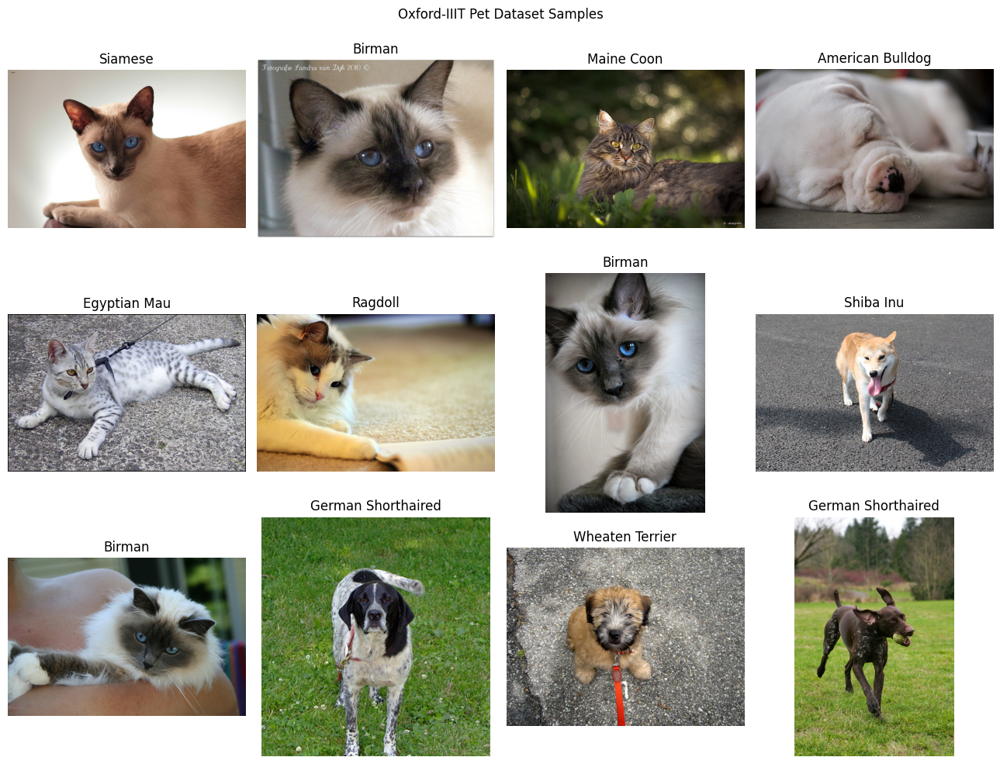

In [277]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(13, 10))

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(trainval),
    size=12,
    replace=False
)

for ax, idx in zip(axes.flat, sample_indices):
    image, label = trainval[int(idx)]

    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Oxford-IIIT Pet Dataset Samples")
plt.tight_layout()
plt.show()


## 2. Train, Validation and Test Split


In [278]:

from sklearn.model_selection import train_test_split

SEED = 42

# Indices of images in the official trainval pool
all_indices = np.arange(len(trainval))

# Stratified splitting preserves class proportions
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Check sizes
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test))

# Verify no overlap within trainval
assert set(train_indices).isdisjoint(set(val_indices))

# Ensure all original trainval samples are allocated
assert len(train_indices) + len(val_indices) == len(trainval)

print("Train/validation split verified!")


Training images: 2944
Validation images: 736
Testing images: 3669
Train/validation split verified!


In [279]:

import pandas as pd
import os

os.makedirs("/kaggle/working/results", exist_ok=True)

split_records = []

for idx in train_indices:
    split_records.append({
        "image_index": int(idx),
        "class_id": int(labels[idx]),
        "split": "train"
    })

for idx in val_indices:
    split_records.append({
        "image_index": int(idx),
        "class_id": int(labels[idx]),
        "split": "validation"
    })

split_df = pd.DataFrame(split_records)

split_df.to_csv(
    "/kaggle/working/results/data_split.csv",
    index=False
)

print(split_df.groupby("split").size())
print("Saved data_split.csv")


split
train         2944
validation     736
dtype: int64
Saved data_split.csv


In [280]:

from collections import Counter
import pandas as pd

train_counts = Counter(labels[train_indices])
val_counts = Counter(labels[val_indices])

rows = []

for class_id, breed in enumerate(class_names):
    rows.append({
        "Breed": breed,
        "Original": int((labels == class_id).sum()),
        "Train": train_counts[class_id],
        "Validation": val_counts[class_id]
    })

distribution_df = pd.DataFrame(rows)

display(distribution_df)

print("\nTotals:")
print(distribution_df[
    ["Original", "Train", "Validation"]
].sum())


,Breed,Original,Train,Validation
0,Abyssinian,100,80,20
1,American Bulldog,100,80,20
2,American Pit Bull Terrier,100,80,20
3,Basset Hound,100,80,20
4,Beagle,100,80,20
5,Bengal,100,80,20
6,Birman,100,80,20
7,Bombay,96,77,19
8,Boxer,100,80,20
9,British Shorthair,100,80,20



Totals:
Original      3680
Train         2944
Validation     736
dtype: int64


## 3. Image Preprocessing and Data Augmentation


In [281]:

from torchvision import transforms

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transforms created successfully!")


Image transforms created successfully!


In [282]:

from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset

DATA_ROOT = "/kaggle/working/data"

train_full = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

val_full = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

test_dataset = OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="category",
    transform=eval_transform,
    download=False
)

train_dataset = Subset(
    train_full,
    train_indices.tolist()
)

val_dataset = Subset(
    val_full,
    val_indices.tolist()
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))


Training: 2944
Validation: 736
Testing: 3669


## 4. DataLoaders


In [283]:

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 92
Validation batches: 23
Testing batches: 115


In [284]:

import torch

images, labels_batch = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels shape:", labels_batch.shape)
print("Image dtype:", images.dtype)
print("Labels dtype:", labels_batch.dtype)

assert images.shape == (32, 3, 224, 224)
assert labels_batch.shape == (32,)
assert torch.isfinite(images).all()

print("\nAll checks passed!")
print("Our data is ready for model training.")


Image shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Labels dtype: torch.int64

All checks passed!
Our data is ready for model training.


Import libraries and set configuration

In [285]:

import os
import random
import time
import copy
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

SEED = 42
EPOCHS_HEAD = 3
EPOCHS_FINETUNE = 10
PATIENCE = 4

LR_HEAD = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

os.makedirs("/kaggle/working/models", exist_ok=True)
os.makedirs("/kaggle/working/results", exist_ok=True)

print("Device:", device)
print("Configuration ready!")


Device: cuda
Configuration ready!


## 5. Pretrained Model Architectures


In [286]:

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "mobilenet_v3_large"
]

def build_model(model_name, num_classes=37):

    if model_name == "resnet18":
        model = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(
            in_features, num_classes
        )

    elif model_name == "mobilenet_v3_large":
        model = models.mobilenet_v3_large(
            weights=models.MobileNet_V3_Large_Weights.DEFAULT
        )

        in_features = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(
            in_features, num_classes
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model


def get_classifier(model, model_name):
    if model_name == "resnet18":
        return model.fc
    return model.classifier


def freeze_backbone(model, model_name):
    for param in model.parameters():
        param.requires_grad = False

    for param in get_classifier(model, model_name).parameters():
        param.requires_grad = True


def unfreeze_all(model):
    for param in model.parameters():
        param.requires_grad = True


print("Model factory ready!")


Model factory ready!


**Write reusable training and validation functions**

In [287]:

def run_epoch(model, loader, criterion, optimizer=None):

    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.detach().cpu().tolist())
        all_labels.extend(labels.detach().cpu().tolist())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels, all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        labels=list(range(37)),
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "macro_f1": epoch_f1
    }


print("Training and validation functions ready!")


Training and validation functions ready!


##**Training function with checkpoints and early stopping**

In [288]:

def train_model(model_name):

    print(f"\n{'=' * 55}")
    print(f"TRAINING: {model_name}")
    print(f"{'=' * 55}")

    set_seed(SEED)

    model = build_model(model_name).to(device)
    criterion = nn.CrossEntropyLoss()

    history = []
    best_f1 = -1.0
    best_state = None
    patience_counter = 0

    start_time = time.time()

    stages = [
        ("head", EPOCHS_HEAD, LR_HEAD),
        ("finetune", EPOCHS_FINETUNE, LR_FINETUNE)
    ]

    for stage_name, max_epochs, lr in stages:

        if stage_name == "head":
            freeze_backbone(model, model_name)
        else:
            unfreeze_all(model)

        optimizer = optim.AdamW(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            lr=lr,
            weight_decay=WEIGHT_DECAY
        )

        patience_counter = 0

        for epoch in range(max_epochs):

            train_metrics = run_epoch(
                model, train_loader,
                criterion, optimizer
            )

            val_metrics = run_epoch(
                model, val_loader, criterion
            )

            record = {
                "model": model_name,
                "stage": stage_name,
                "epoch": len(history) + 1,
                "train_loss": train_metrics["loss"],
                "train_accuracy": train_metrics["accuracy"],
                "train_f1": train_metrics["macro_f1"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "val_f1": val_metrics["macro_f1"]
            }

            history.append(record)

            print(
                f"{stage_name} | Epoch {epoch+1}/{max_epochs} | "
                f"Train Acc: {train_metrics['accuracy']:.4f} | "
                f"Val Acc: {val_metrics['accuracy']:.4f} | "
                f"Val F1: {val_metrics['macro_f1']:.4f}"
            )

            if val_metrics["macro_f1"] > best_f1:

                best_f1 = val_metrics["macro_f1"]
                best_state = copy.deepcopy(model.state_dict())
                patience_counter = 0

                torch.save(
                    {
                        "model_name": model_name,
                        "state_dict": best_state,
                        "val_macro_f1": best_f1,
                        "class_names": class_names
                    },
                    f"/kaggle/working/models/{model_name}_best.pth"
                )

            else:
                patience_counter += 1

            if (
                stage_name == "finetune"
                and patience_counter >= PATIENCE
            ):
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)

    total_time = time.time() - start_time

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        f"/kaggle/working/results/{model_name}_history.csv",
        index=False
    )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"Best validation macro-F1: {best_f1:.4f}")
    print(f"Training time: {total_time/60:.2f} minutes")

    return {
        "model": model_name,
        "best_val_f1": best_f1,
        "training_minutes": total_time / 60
    }


print("Complete training pipeline ready!")


Complete training pipeline ready!


## 6. Model Training and Fine-Tuning


In [289]:

assert device.type == "cuda", (
    "Enable a Kaggle GPU before starting all models."
)

comparison_results = []

for model_name in MODEL_NAMES:

    result = train_model(model_name)

    comparison_results.append(result)

    pd.DataFrame(comparison_results).to_csv(
        "/kaggle/working/results/model_comparison.csv",
        index=False
    )

print("\nTraining completed!")
display(pd.DataFrame(comparison_results))



TRAINING: resnet18
head | Epoch 1/3 | Train Acc: 0.4755 | Val Acc: 0.8016 | Val F1: 0.7925
head | Epoch 2/3 | Train Acc: 0.8132 | Val Acc: 0.8628 | Val F1: 0.8612
head | Epoch 3/3 | Train Acc: 0.8709 | Val Acc: 0.8791 | Val F1: 0.8791
finetune | Epoch 1/10 | Train Acc: 0.8862 | Val Acc: 0.8995 | Val F1: 0.8999
finetune | Epoch 2/10 | Train Acc: 0.9528 | Val Acc: 0.8832 | Val F1: 0.8825
finetune | Epoch 3/10 | Train Acc: 0.9823 | Val Acc: 0.9103 | Val F1: 0.9114
finetune | Epoch 4/10 | Train Acc: 0.9857 | Val Acc: 0.9049 | Val F1: 0.9049
finetune | Epoch 5/10 | Train Acc: 0.9946 | Val Acc: 0.9198 | Val F1: 0.9201
finetune | Epoch 6/10 | Train Acc: 0.9959 | Val Acc: 0.9171 | Val F1: 0.9173
finetune | Epoch 7/10 | Train Acc: 0.9990 | Val Acc: 0.9076 | Val F1: 0.9077
finetune | Epoch 8/10 | Train Acc: 0.9983 | Val Acc: 0.9144 | Val F1: 0.9148
finetune | Epoch 9/10 | Train Acc: 0.9986 | Val Acc: 0.9117 | Val F1: 0.9118
Early stopping triggered.
Best validation macro-F1: 0.9201
Training tim

,model,best_val_f1,training_minutes
0,resnet18,0.920093,2.948809
1,efficientnet_b0,0.931547,3.631727
2,mobilenet_v3_large,0.901854,3.151976


**Compare validation performance**

In [290]:

comparison_df = pd.read_csv(
    "/kaggle/working/results/model_comparison.csv"
)

comparison_df = comparison_df.sort_values(
    "best_val_f1",
    ascending=False
)

display(comparison_df)

best_model_name = comparison_df.iloc[0]["model"]

print("\nSelected model:", best_model_name)
print(
    "Validation macro-F1:",
    comparison_df.iloc[0]["best_val_f1"]
)


,model,best_val_f1,training_minutes
1,efficientnet_b0,0.931547,3.631727
0,resnet18,0.920093,2.948809
2,mobilenet_v3_large,0.901854,3.151976



Selected model: efficientnet_b0
Validation macro-F1: 0.9315465043902604


## 7. Training and Validation Curves


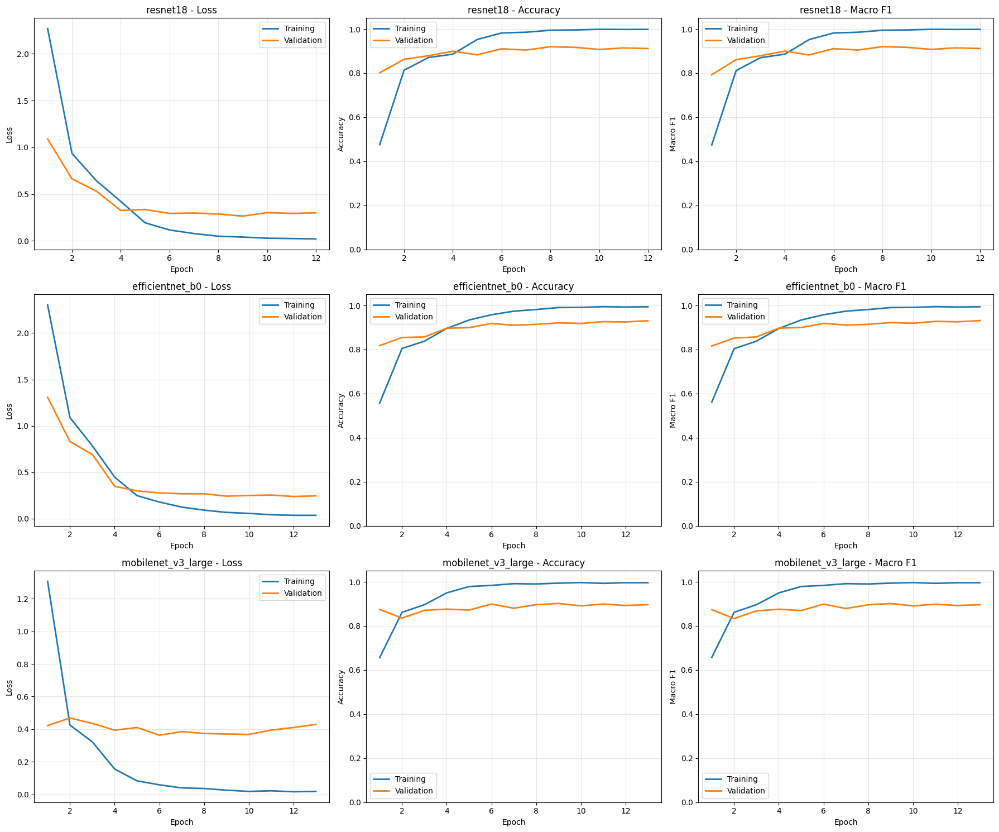

In [291]:

fig, axes = plt.subplots(
    3, 3, figsize=(18, 15)
)

metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("f1", "Macro F1")
]

for row, model_name in enumerate(MODEL_NAMES):

    history = pd.read_csv(
        f"{RESULTS_DIR}/{model_name}_history.csv"
    )

    for col, (metric, title) in enumerate(metrics):

        ax = axes[row, col]

        ax.plot(
            history["epoch"],
            history[f"train_{metric}"],
            label="Training",
            linewidth=2
        )

        ax.plot(
            history["epoch"],
            history[f"val_{metric}"],
            label="Validation",
            linewidth=2
        )

        ax.set_title(f"{model_name} - {title}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)
        ax.legend()

        if metric != "loss":
            ax.set_ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/all_models_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


## 8. Model Evaluation


### 8.1 Accuracy, Precision, Recall and F1-Score


In [292]:

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

RESULTS_DIR = "/kaggle/working/results"
MODELS_DIR = "/kaggle/working/models"

os.makedirs(RESULTS_DIR, exist_ok=True)

MODEL_NAMES = [
    "resnet18",
    "efficientnet_b0",
    "mobilenet_v3_large"
]

NUM_CLASSES = 37
class_ids = np.arange(NUM_CLASSES)

evaluation_results = {}
comparison_rows = []

@torch.inference_mode()
def get_predictions(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    for images, targets in loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(targets.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

    return (
        np.asarray(all_labels),
        np.asarray(all_predictions),
        np.asarray(all_probabilities)
    )


for model_name in MODEL_NAMES:

    print(f"\nEvaluating {model_name}...")

    checkpoint_path = (
        f"{MODELS_DIR}/{model_name}_best.pth"
    )

    assert os.path.exists(checkpoint_path), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model = build_model(
        model_name, num_classes=NUM_CLASSES
    )

    model.load_state_dict(checkpoint["state_dict"])
    model = model.to(device)

    y_true, y_pred, y_prob = get_predictions(
        model, val_loader
    )

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        )
    )

    evaluation_results[model_name] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {f1:.4f}")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)



Evaluating resnet18...
Accuracy: 0.9198
Macro F1: 0.9201

Evaluating efficientnet_b0...
Accuracy: 0.9307
Macro F1: 0.9315

Evaluating mobilenet_v3_large...
Accuracy: 0.9022
Macro F1: 0.9019


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,resnet18,0.919837,0.926688,0.919772,0.920093
1,efficientnet_b0,0.930707,0.934884,0.931081,0.931547
2,mobilenet_v3_large,0.902174,0.907000,0.902347,0.901854


### 8.2 Confusion Matrices and  Top Three Breed Confusions

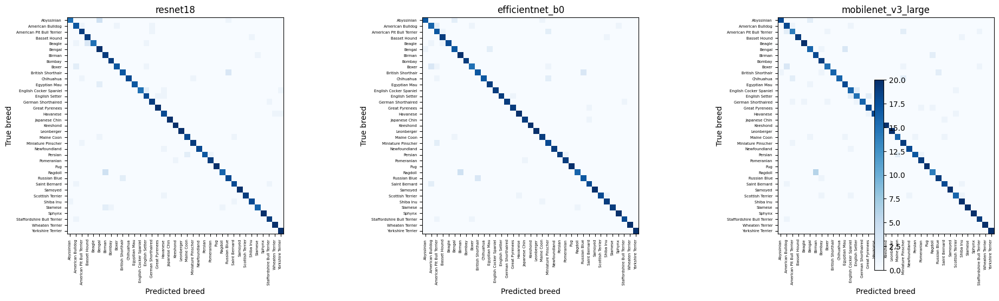


Top confusions: resnet18


,Model,Actual Breed,Predicted Breed,Errors
0,resnet18,Abyssinian,Bengal,4
32,resnet18,Ragdoll,Birman,4
8,resnet18,Beagle,Basset Hound,3



Top confusions: efficientnet_b0


,Model,Actual Breed,Predicted Breed,Errors
69,efficientnet_b0,Ragdoll,Birman,4
58,efficientnet_b0,British Shorthair,Russian Blue,3
70,efficientnet_b0,Russian Blue,British Shorthair,3



Top confusions: mobilenet_v3_large


,Model,Actual Breed,Predicted Breed,Errors
121,mobilenet_v3_large,Ragdoll,Birman,6
87,mobilenet_v3_large,Bengal,Egyptian Mau,3
89,mobilenet_v3_large,Boxer,American Bulldog,3


In [293]:

fig, axes = plt.subplots(
    1, 3, figsize=(23, 7)
)

confusion_summaries = []

for ax, model_name in zip(axes, MODEL_NAMES):

    result = evaluation_results[model_name]

    cm = confusion_matrix(
        result["y_true"],
        result["y_pred"],
        labels=class_ids
    )

    im = ax.imshow(
        cm, interpolation="nearest",
        cmap="Blues"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted breed")
    ax.set_ylabel("True breed")

    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))

    ax.set_xticklabels(
        class_names, rotation=90, fontsize=5
    )
    ax.set_yticklabels(class_names, fontsize=5)

    # Save full classification report
    report = classification_report(
        result["y_true"],
        result["y_pred"],
        labels=class_ids,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        f"{RESULTS_DIR}/{model_name}_class_report.csv"
    )

    # Identify most frequent directional confusions
    errors = cm.copy()
    np.fill_diagonal(errors, 0)

    for true_id, pred_id in zip(
        *np.where(errors > 0)
    ):
        confusion_summaries.append({
            "Model": model_name,
            "Actual Breed": class_names[true_id],
            "Predicted Breed": class_names[pred_id],
            "Errors": int(errors[true_id, pred_id])
        })

    np.savetxt(
        f"{RESULTS_DIR}/{model_name}_confusion_matrix.csv",
        cm,
        delimiter=",",
        fmt="%d"
    )

fig.colorbar(im, ax=axes.tolist(), shrink=0.65)
fig.subplots_adjust(
    left=0.12,
    right=0.88,
    bottom=0.34,
    top=0.91,
    wspace=0.5
)

fig.savefig(
    f"{RESULTS_DIR}/all_models_confusion_matrices.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

confusions_df = pd.DataFrame(confusion_summaries)

for model_name in MODEL_NAMES:
    print(f"\nTop confusions: {model_name}")

    top3 = (
        confusions_df[
            confusions_df["Model"] == model_name
        ]
        .sort_values("Errors", ascending=False)
        .head(3)
    )

    display(top3)


### 8.3 ROC Curves and AUC


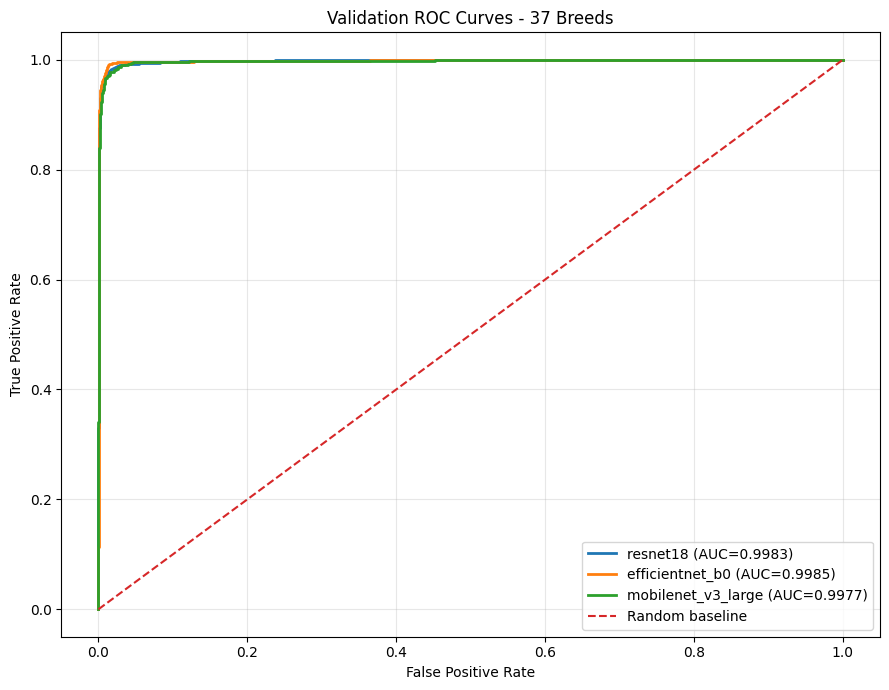

,Model,Micro AUC,Macro AUC
0,resnet18,0.998270,0.998134
1,efficientnet_b0,0.998510,0.998141
2,mobilenet_v3_large,0.997702,0.997672


In [294]:

fig, ax = plt.subplots(figsize=(9, 7))

auc_rows = []

for model_name in MODEL_NAMES:

    result = evaluation_results[model_name]

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    # Convert integer labels into one-hot vectors
    y_binary = np.eye(NUM_CLASSES)[y_true]

    # Micro-average ROC
    fpr, tpr, _ = roc_curve(
        y_binary.ravel(),
        y_prob.ravel()
    )

    micro_auc = auc(fpr, tpr)

    macro_auc = roc_auc_score(
        y_binary,
        y_prob,
        average="macro"
    )

    auc_rows.append({
        "Model": model_name,
        "Micro AUC": micro_auc,
        "Macro AUC": macro_auc
    })

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC={micro_auc:.4f})"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("Validation ROC Curves - 37 Breeds")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/all_models_roc.png",
    dpi=200
)
plt.show()

auc_df = pd.DataFrame(auc_rows)
display(auc_df)


## 9. Model Comparison and Best Model Selection


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro AUC,Macro AUC
1,efficientnet_b0,0.9307,0.9349,0.9311,0.9315,0.9985,0.9981
0,resnet18,0.9198,0.9267,0.9198,0.9201,0.9983,0.9981
2,mobilenet_v3_large,0.9022,0.9070,0.9023,0.9019,0.9977,0.9977


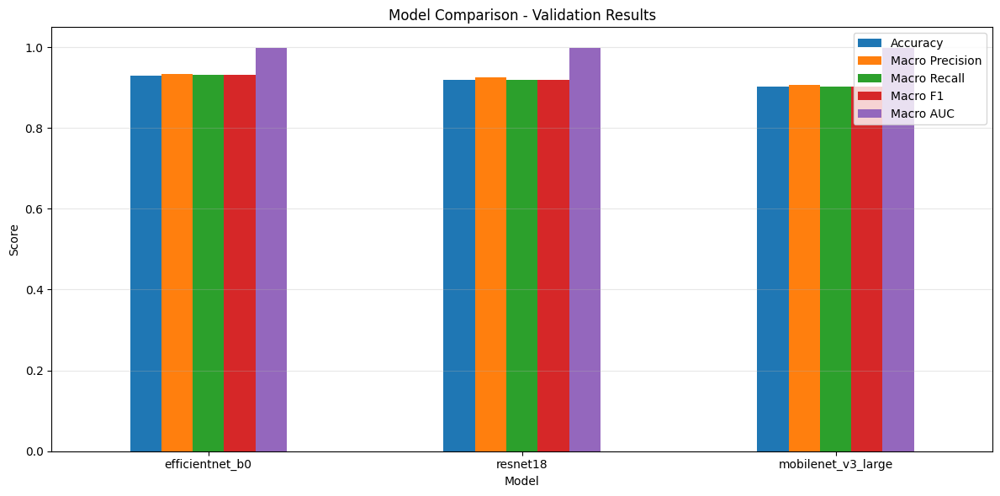

Selected model: efficientnet_b0
Validation macro-F1: 0.9315465043902604


In [295]:

comparison_df = comparison_df.merge(
    auc_df, on="Model"
)

comparison_df = comparison_df.sort_values(
    "Macro F1",
    ascending=False
)

comparison_df.to_csv(
    f"{RESULTS_DIR}/complete_model_comparison.csv",
    index=False
)

display(
    comparison_df.style.format({
        col: "{:.4f}"
        for col in comparison_df.columns
        if col != "Model"
    })
)

metric_cols = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Macro AUC"
]

ax = comparison_df.set_index("Model")[
    metric_cols
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    rot=0
)

ax.set_title("Model Comparison - Validation Results")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/model_comparison_chart.png",
    dpi=200
)
plt.show()

best_model_name = comparison_df.iloc[0]["Model"]

print("Selected model:", best_model_name)
print(
    "Validation macro-F1:",
    comparison_df.iloc[0]["Macro F1"]
)


### 9.1 Per-Class Classification Report of Best model


In [296]:

import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import models
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = (
    "/kaggle/working/models/efficientnet_b0_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model = models.efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 37)

model.load_state_dict(checkpoint["state_dict"])

model = model.to(device)
model.eval()

class_names = checkpoint["class_names"]

print("EfficientNet-B0 loaded successfully!")
print("Number of breeds:", len(class_names))
print("Device:", device)


EfficientNet-B0 loaded successfully!
Number of breeds: 37
Device: cuda


In [297]:

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

os.makedirs("/kaggle/working/results", exist_ok=True)

# 'model' is our loaded EfficientNet-B0
# 'test_loader' is the official Oxford test DataLoader

model.eval()

test_true, test_pred, test_prob = get_predictions(
    model, test_loader
)

test_accuracy = accuracy_score(
    test_true, test_pred
)

test_precision = precision_score(
    test_true, test_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_true, test_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_true, test_pred,
    average="macro",
    zero_division=0
)

print("EFF IC IENTNET-B0: FINAL TEST RESULTS")
print("=" * 45)

print(f"Accuracy:        {test_accuracy:.4%}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall:    {test_recall:.4f}")
print(f"Macro F1:        {test_f1:.4f}")

# Complete report covering all 37 breeds
report = classification_report(
    test_true,
    test_pred,
    labels=np.arange(37),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(report_df)

report_df.to_csv(
    "/kaggle/working/results/"
    "efficientnet_test_per_class.csv"
)

print("Per-class results saved!")


EFF IC IENTNET-B0: FINAL TEST RESULTS
Accuracy:        90.2426%
Macro Precision: 0.9053
Macro Recall:    0.9022
Macro F1:        0.9004


,precision,recall,f1-score,support
Abyssinian,0.941860,0.826531,0.880435,98.000000
American Bulldog,0.726496,0.850000,0.783410,100.000000
American Pit Bull Terrier,0.826923,0.430000,0.565789,100.000000
Basset Hound,0.958333,0.920000,0.938776,100.000000
Beagle,0.895238,0.940000,0.917073,100.000000
Bengal,0.756522,0.870000,0.809302,100.000000
Birman,0.784483,0.910000,0.842593,100.000000
Bombay,0.833333,0.965909,0.894737,88.000000
Boxer,0.844037,0.929293,0.884615,99.000000
British Shorthair,0.930233,0.800000,0.860215,100.000000


Per-class results saved!


### 9.2 Confusion Matrices of Best Model

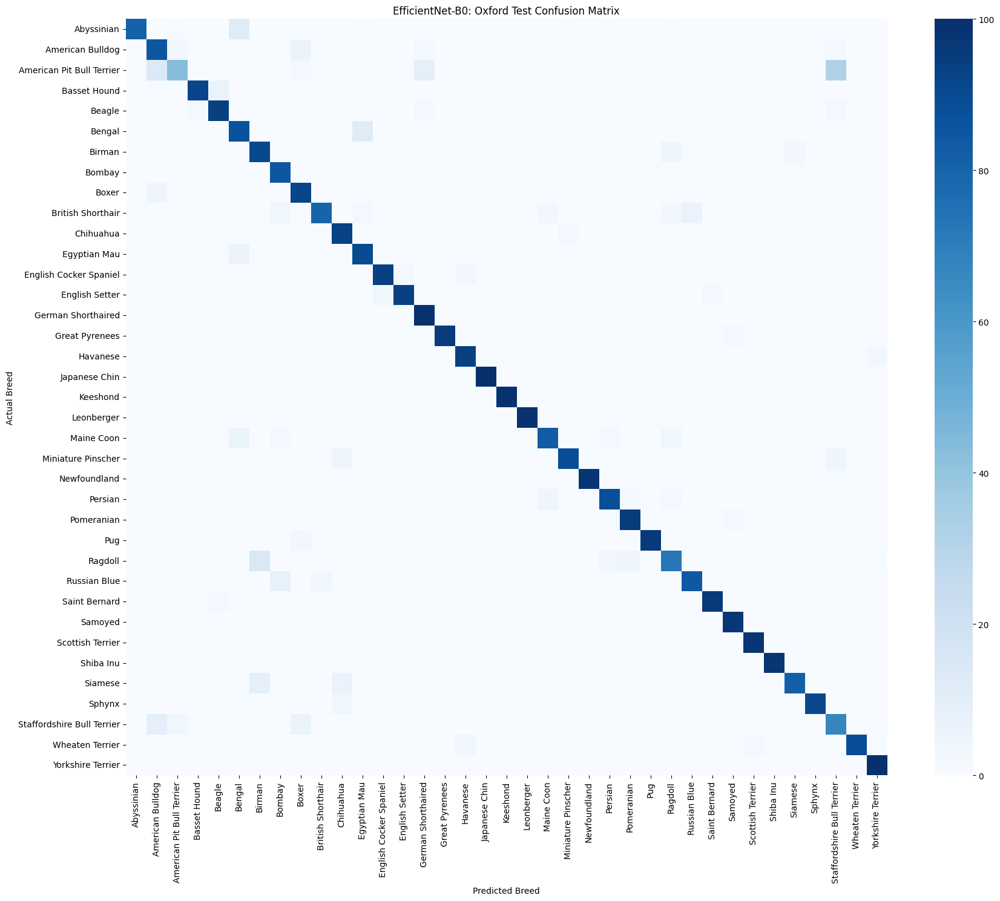

In [298]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    test_true,
    test_pred,
    labels=np.arange(37)
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False
)

plt.title("EfficientNet-B0: Oxford Test Confusion Matrix")
plt.xlabel("Predicted Breed")
plt.ylabel("Actual Breed")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/results/"
    "efficientnet_test_confusion_matrix.png",
    dpi=250
)

plt.show()


### 9.3 Top Three Breed Confusions of Best Model


In [299]:

cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

error_rows = []

for true_idx in range(37):
    for pred_idx in range(37):

        count = cm_errors[true_idx, pred_idx]

        if count > 0:
            error_rows.append({
                "Actual Breed": class_names[true_idx],
                "Predicted Breed": class_names[pred_idx],
                "Mistakes": int(count)
            })

errors_df = pd.DataFrame(error_rows)

errors_df = errors_df.sort_values(
    "Mistakes",
    ascending=False
)

print("TOP 3 BREED CONFUSIONS")
display(errors_df.head(3))

errors_df.to_csv(
    "/kaggle/working/results/"
    "efficientnet_test_confusions.csv",
    index=False
)


TOP 3 BREED CONFUSIONS


,Actual Breed,Predicted Breed,Mistakes
15,American Pit Bull Terrier,Staffordshire Bull Terrier,32
85,Ragdoll,Birman,15
12,American Pit Bull Terrier,American Bulldog,14


## 10. Internet Image Prediction


In [300]:

import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import models
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = (
    "/kaggle/working/models/efficientnet_b0_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model = models.efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 37)

model.load_state_dict(checkpoint["state_dict"])

model = model.to(device)
model.eval()

class_names = checkpoint["class_names"]

print("EfficientNet-B0 loaded successfully!")
print("Number of breeds:", len(class_names))
print("Device:", device)


EfficientNet-B0 loaded successfully!
Number of breeds: 37
Device: cuda


In [301]:

import numpy as np

@torch.inference_mode()
def predict_pet(image, top_k=3):

    image = image.convert("RGB")

    # Same preprocessing used for validation
    image_tensor = eval_transform(image)

    # Add batch dimension
    image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    # Model output
    logits = model(image_tensor)

    # Convert logits to probabilities
    probabilities = F.softmax(logits, dim=1)[0]

    # Top K predictions
    scores, indices = torch.topk(
        probabilities,
        k=top_k
    )

    predictions = []

    for score, index in zip(scores, indices):
        predictions.append({
            "breed": class_names[index.item()],
            "confidence": float(score.item())
        })

    return predictions

print("Prediction function ready!")


Prediction function ready!


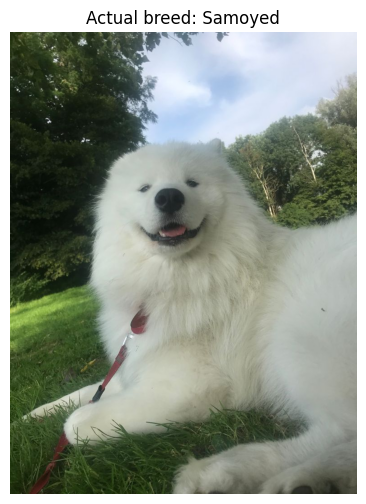

Top 3 predictions:

Samoyed: 53.47%
Great Pyrenees: 46.33%
Newfoundland: 0.04%

Correct prediction: True


In [302]:

import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Wikimedia Commons direct image redirect
IMAGE_URL = (
    "https://commons.wikimedia.org/wiki/"
    "Special:Redirect/file/Samoyed_dog.jpg"
)

response = requests.get(
    IMAGE_URL,
    timeout=40,
    headers={"User-Agent": "PetBreedResearch/1.0"}
)

response.raise_for_status()

image = Image.open(
    BytesIO(response.content)
).convert("RGB")

# Our trained EfficientNet-B0
predictions = predict_pet(image)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Actual breed: Samoyed")
plt.show()

print("Top 3 predictions:\n")

for result in predictions:
    print(
        f"{result['breed']}: "
        f"{result['confidence'] * 100:.2f}%"
    )

print("\nCorrect prediction:",
      predictions[0]["breed"] == "Samoyed")


## 11. External Dataset Collection and Visualization


In [303]:

import requests
from pathlib import Path
from collections import Counter

OWNER = "AtharvaTaras"
REPO = "Cat-Breeds-Dataset"

session = requests.Session()
session.headers.update({
    "Accept": "application/vnd.github+json",
    "User-Agent": "PetBreedInternshipResearch"
})

repo_response = session.get(
    f"https://api.github.com/repos/{OWNER}/{REPO}",
    timeout=30
)
repo_response.raise_for_status()

branch = repo_response.json()["default_branch"]

tree_response = session.get(
    f"https://api.github.com/repos/{OWNER}/{REPO}/git/trees/{branch}",
    params={"recursive": 1},
    timeout=60
)
tree_response.raise_for_status()

tree_data = tree_response.json()

if tree_data.get("truncated"):
    raise RuntimeError(
        "GitHub returned a truncated repository tree."
    )

all_files = [
    item["path"]
    for item in tree_data["tree"]
    if item["type"] == "blob"
    and item["path"].lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp")
    )
    and item["path"].startswith("images/")
]

print("Total image files found:", len(all_files))
print("\nFirst 20 image paths:")

for path in all_files[:20]:
    print(path)

print("\nExample directory structure:")
for folder, count in Counter(
    str(Path(p).parent) for p in all_files
).most_common(15):
    print(folder, count)


Total image files found: 4835

First 20 image paths:
images/abyssinian_cat/000.png
images/abyssinian_cat/001.png
images/abyssinian_cat/002.png
images/abyssinian_cat/003.png
images/abyssinian_cat/004.png
images/abyssinian_cat/005.png
images/abyssinian_cat/006.png
images/abyssinian_cat/007.png
images/abyssinian_cat/008.png
images/abyssinian_cat/009.png
images/abyssinian_cat/010.png
images/abyssinian_cat/011.png
images/abyssinian_cat/012.png
images/abyssinian_cat/013.png
images/abyssinian_cat/014.png
images/abyssinian_cat/015.png
images/abyssinian_cat/016.png
images/abyssinian_cat/017.png
images/abyssinian_cat/018.png
images/abyssinian_cat/019.png

Example directory structure:
images/maine_coon_cat 379
images/scottish_fold_cat 305
images/siamese_cat 305
images/sphynx_cat 302
images/persian_cat 279
images/ragdoll_cat 245
images/oriental_shorthair_cat 240
images/abyssinian_cat 234
images/bengal_cat 233
images/manx_cat 231
images/cornish_rex_cat 229
images/himalayan_cat 219
images/birman_cat

In [304]:

import random
import pandas as pd
import requests
from pathlib import Path
from PIL import Image
from io import BytesIO
from urllib.parse import quote

random.seed(42)

BASE = Path("/kaggle/working/external_cats")
IMG_DIR = BASE / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)

TARGET_BREEDS = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Maine Coon",
    "Persian",
    "Ragdoll",
    "Russian Blue",
    "Siamese",
    "Sphynx"
]

IMAGES_PER_BREED = 5

def normalize_name(name):
    return "".join(
        c for c in name.lower()
        if c.isalnum()
    )

records = []

for breed in TARGET_BREEDS:

    # Actual repository directory format:
    # images/abyssinian_cat/000.png
    expected_folder = normalize_name(breed) + "cat"

    matches = [
        path for path in all_files
        if len(Path(path).parts) >= 3
        and normalize_name(
            Path(path).parent.name
        ) == expected_folder
    ]

    random.shuffle(matches)
    downloaded = 0

    for path in matches:

        if downloaded >= IMAGES_PER_BREED:
            break

        url = (
            f"https://raw.githubusercontent.com/"
            f"{OWNER}/{REPO}/{branch}/"
            f"{quote(path, safe='/')}"
        )

        try:
            response = session.get(url, timeout=30)
            response.raise_for_status()

            img = Image.open(
                BytesIO(response.content)
            ).convert("RGB")

            if min(img.size) < 180:
                continue

            filename = (
                f"{normalize_name(breed)}_"
                f"{downloaded+1:02d}.jpg"
            )

            img.save(
                IMG_DIR / filename,
                quality=95
            )

            records.append({
                "filename": filename,
                "breed": breed,
                "source": url,
                "verified": False
            })

            downloaded += 1

        except Exception as exc:
            print("Skipped:", str(exc)[:100])

    print(
        f"{breed}: {downloaded} images "
        f"(available: {len(matches)})"
    )

df = pd.DataFrame(records)

df.to_csv(
    BASE / "external_labels.csv",
    index=False
)

print("\nTOTAL DOWNLOADED:", len(df))
print("TARGET:", len(TARGET_BREEDS) * IMAGES_PER_BREED)
print("Saved to:", BASE)


Abyssinian: 5 images (available: 234)
Bengal: 5 images (available: 233)
Birman: 5 images (available: 216)
Maine Coon: 5 images (available: 379)
Persian: 5 images (available: 279)
Ragdoll: 5 images (available: 245)
Russian Blue: 5 images (available: 205)
Siamese: 5 images (available: 305)
Sphynx: 5 images (available: 302)

TOTAL DOWNLOADED: 45
TARGET: 45
Saved to: /kaggle/working/external_cats


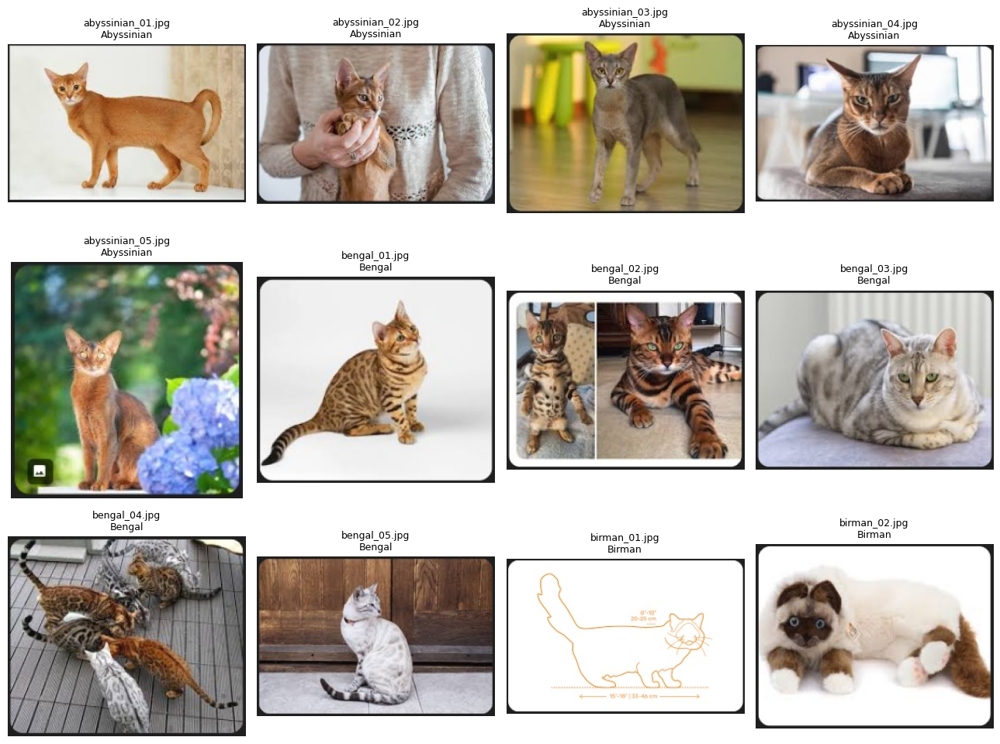

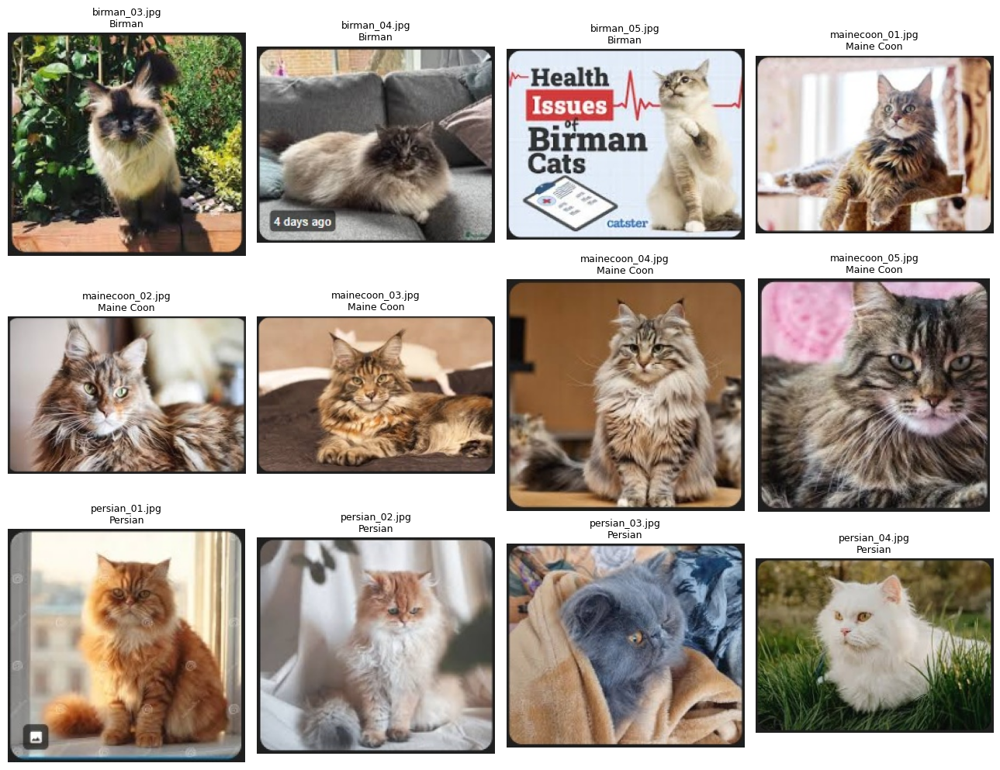

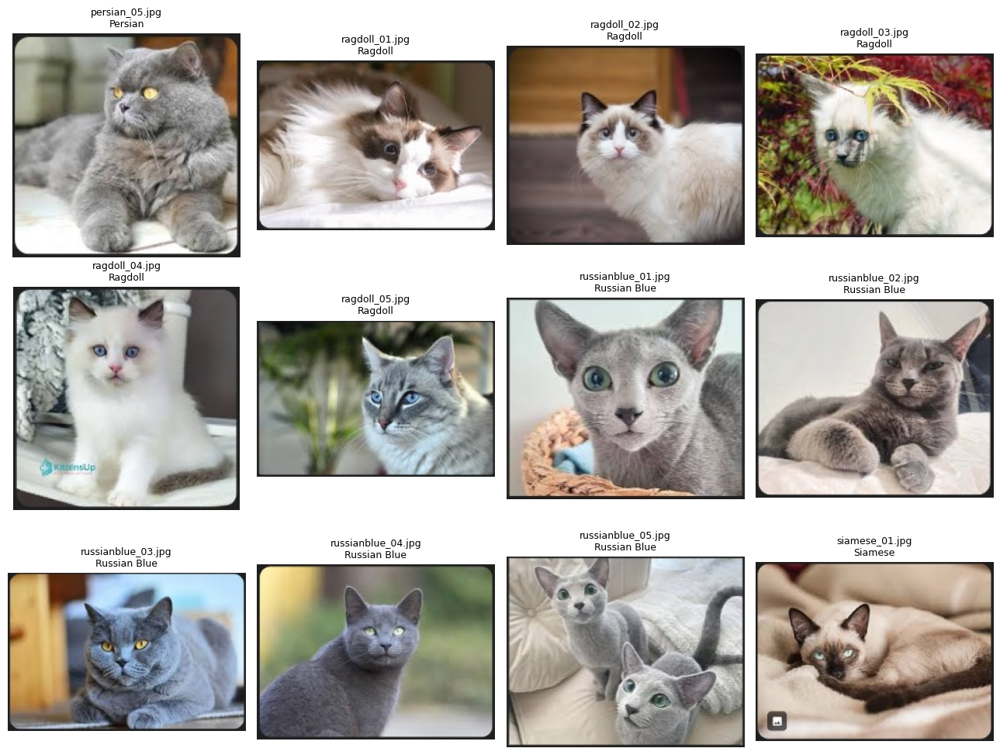

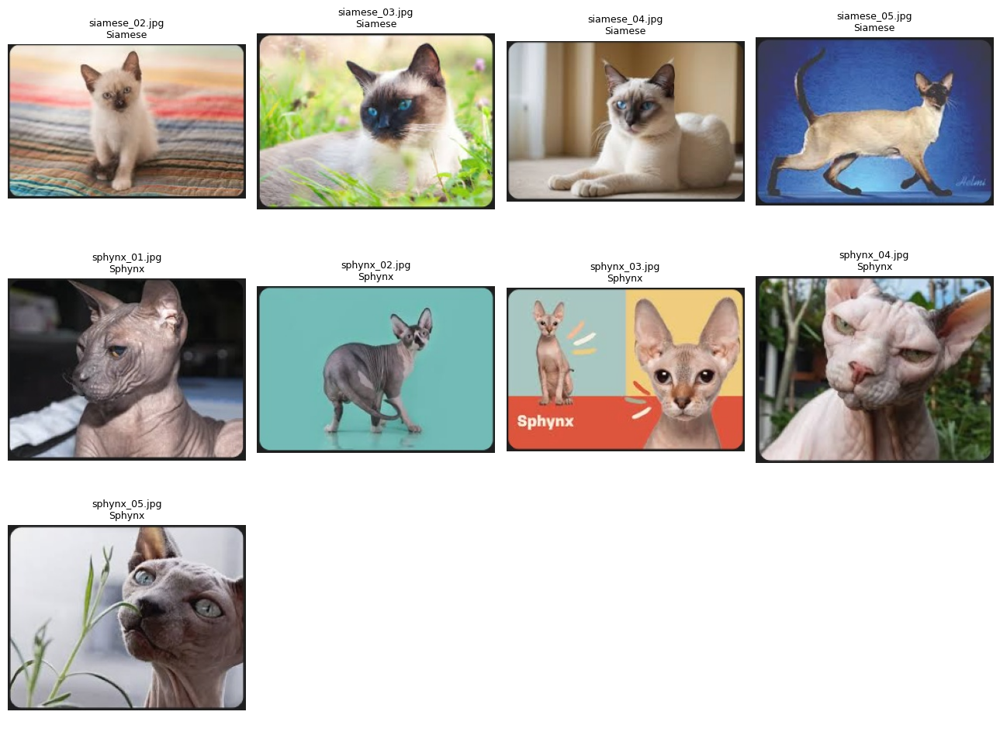

In [305]:

import matplotlib.pyplot as plt
from PIL import Image

for start in range(0, len(df), 12):

    batch = df.iloc[start:start + 12]

    fig, axes = plt.subplots(
        3, 4, figsize=(13, 10)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes.flat,
        batch.iterrows()
    ):

        image = Image.open(
            IMG_DIR / row["filename"]
        )

        ax.imshow(image)

        ax.set_title(
            f"{row['filename']}\n{row['breed']}",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()


In [306]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/external_cats/external_labels.csv"
)

exclude_files = {
    "birman_01.jpg",
    "birman_05.jpg",
    "sphynx_03.jpg",
    "bengal_02.jpg"
}

df["include"] = ~df["filename"].isin(exclude_files)

# Visual screening is not full breed verification.
df["verified"] = False

df.to_csv(
    "/kaggle/working/external_cats/reviewed_labels.csv",
    index=False
)

print("Original images:", len(df))
print("Retained candidates:", df["include"].sum())
print("Excluded:", (~df["include"]).sum())

display(df[~df["include"]])


Original images: 45
Retained candidates: 41
Excluded: 4


,filename,breed,source,verified,include
6,bengal_02.jpg,Bengal,https://raw.githubusercontent.com/AtharvaTaras...,False,False
10,birman_01.jpg,Birman,https://raw.githubusercontent.com/AtharvaTaras...,False,False
14,birman_05.jpg,Birman,https://raw.githubusercontent.com/AtharvaTaras...,False,False
42,sphynx_03.jpg,Sphynx,https://raw.githubusercontent.com/AtharvaTaras...,False,False


In [307]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/external_cats/reviewed_labels.csv"
)

print("Total images:", len(df))
print("Included images:", df["include"].sum())
print("Verified images:", df["verified"].sum())

display(df[["filename", "breed", "include", "verified"]])


Total images: 45
Included images: 41
Verified images: 0


,filename,breed,include,verified
0,abyssinian_01.jpg,Abyssinian,True,False
1,abyssinian_02.jpg,Abyssinian,True,False
2,abyssinian_03.jpg,Abyssinian,True,False
3,abyssinian_04.jpg,Abyssinian,True,False
4,abyssinian_05.jpg,Abyssinian,True,False
5,bengal_01.jpg,Bengal,True,False
6,bengal_02.jpg,Bengal,False,False
7,bengal_03.jpg,Bengal,True,False
8,bengal_04.jpg,Bengal,True,False
9,bengal_05.jpg,Bengal,True,False


## 12. External Generalisation Evaluation


In [308]:

import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.metrics import accuracy_score

BASE = Path("/kaggle/working/external_cats")
IMG_DIR = BASE / "images"

df = pd.read_csv(BASE / "reviewed_labels.csv")

# Use the 41 retained images
approved = df[df["include"] == True].copy()

print("Images for evaluation:", len(approved))

results = []

for _, row in approved.iterrows():

    image = Image.open(
        IMG_DIR / row["filename"]
    ).convert("RGB")

    predictions = predict_pet(image, top_k=3)

    actual = row["breed"]
    predicted = predictions[0]["breed"]

    results.append({
        "filename": row["filename"],
        "actual": actual,
        "predicted": predicted,
        "confidence": predictions[0]["confidence"],
        "correct": actual == predicted,
        "second_prediction": predictions[1]["breed"],
        "source": row["source"]
    })

external_results = pd.DataFrame(results)

external_accuracy = accuracy_score(
    external_results["actual"],
    external_results["predicted"]
)

print("\nEXTERNAL DATASET RESULTS")
print("=" * 40)
print("Images:", len(external_results))
print(f"Preliminary accuracy: {external_accuracy:.2%}")
print("Correct:", external_results["correct"].sum())
print("Incorrect:", (~external_results["correct"]).sum())

display(external_results)

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(exist_ok=True)

external_results.to_csv(
    RESULTS_DIR / "external_predictions.csv",
    index=False
)


Images for evaluation: 41

EXTERNAL DATASET RESULTS
Images: 41
Preliminary accuracy: 53.66%
Correct: 22
Incorrect: 19


,filename,actual,predicted,confidence,correct,second_prediction,source
0,abyssinian_01.jpg,Abyssinian,Abyssinian,0.982870,True,Miniature Pinscher,https://raw.githubusercontent.com/AtharvaTaras...
1,abyssinian_02.jpg,Abyssinian,Bengal,0.686871,False,Abyssinian,https://raw.githubusercontent.com/AtharvaTaras...
2,abyssinian_03.jpg,Abyssinian,Abyssinian,0.864610,True,Chihuahua,https://raw.githubusercontent.com/AtharvaTaras...
3,abyssinian_04.jpg,Abyssinian,Bengal,0.967991,False,Abyssinian,https://raw.githubusercontent.com/AtharvaTaras...
4,abyssinian_05.jpg,Abyssinian,Abyssinian,0.998464,True,Miniature Pinscher,https://raw.githubusercontent.com/AtharvaTaras...
5,bengal_01.jpg,Bengal,Bengal,0.768050,True,Egyptian Mau,https://raw.githubusercontent.com/AtharvaTaras...
6,bengal_03.jpg,Bengal,Bengal,0.530030,True,Egyptian Mau,https://raw.githubusercontent.com/AtharvaTaras...
7,bengal_04.jpg,Bengal,Bengal,0.924195,True,Miniature Pinscher,https://raw.githubusercontent.com/AtharvaTaras...
8,bengal_05.jpg,Bengal,Egyptian Mau,0.742751,False,Bengal,https://raw.githubusercontent.com/AtharvaTaras...
9,birman_02.jpg,Birman,Chihuahua,0.394771,False,American Pit Bull Terrier,https://raw.githubusercontent.com/AtharvaTaras...


In [309]:

from sklearn.metrics import classification_report

print("EXTERNAL BREED-LEVEL RESULTS")

report = classification_report(
    external_results["actual"],
    external_results["predicted"],
    labels=sorted(external_results["actual"].unique()),
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(report_df)

report_df.to_csv(
    RESULTS_DIR / "external_classification_report.csv"
)


EXTERNAL BREED-LEVEL RESULTS


,precision,recall,f1-score,support
Abyssinian,1.000000,0.600000,0.750000,5.0
Bengal,0.500000,0.750000,0.600000,4.0
Birman,1.000000,0.333333,0.500000,3.0
Maine Coon,0.714286,1.000000,0.833333,5.0
Persian,0.500000,0.200000,0.285714,5.0
Ragdoll,1.000000,0.400000,0.571429,5.0
Russian Blue,1.000000,0.200000,0.333333,5.0
Siamese,1.000000,0.600000,0.750000,5.0
Sphynx,1.000000,0.750000,0.857143,4.0
micro avg,0.785714,0.536585,0.637681,41.0


In [310]:

accuracy_difference = (
    external_accuracy - test_accuracy
) * 100

print("GENERALISATION COMPARISON")
print("=" * 40)

print(f"Oxford test accuracy: {test_accuracy:.2%}")
print(f"External accuracy:    {external_accuracy:.2%}")

print(
    f"Accuracy change: {accuracy_difference:+.2f} "
    "percentage points"
)


GENERALISATION COMPARISON
Oxford test accuracy: 90.24%
External accuracy:    53.66%
Accuracy change: -36.58 percentage points


Total misclassified images: 19


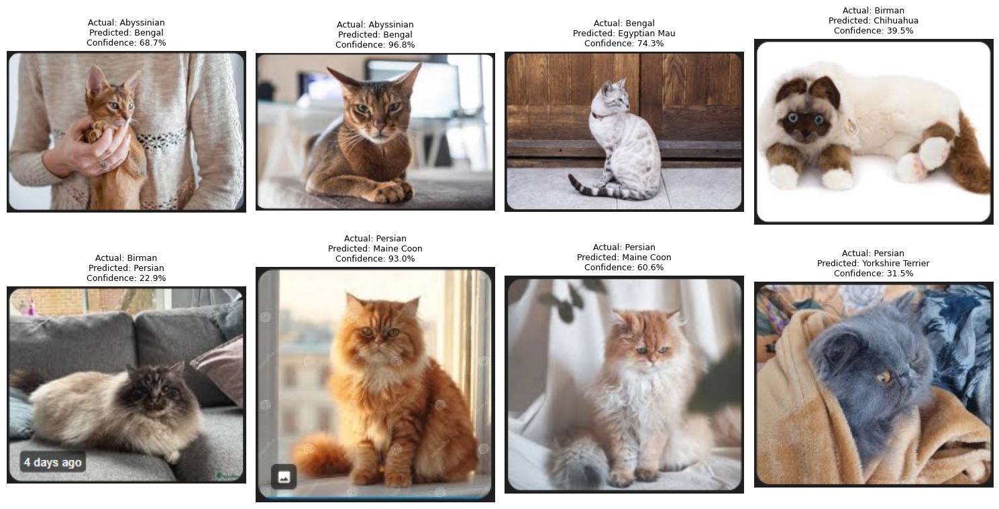

In [311]:

import matplotlib.pyplot as plt

failures = external_results[
    external_results["correct"] == False
].copy()

print("Total misclassified images:", len(failures))

if len(failures) > 0:

    sample = failures.head(8)

    fig, axes = plt.subplots(
        2, 4, figsize=(15, 8)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes.flat, sample.iterrows()
    ):

        image = Image.open(
            IMG_DIR / row["filename"]
        )

        ax.imshow(image)

        ax.set_title(
            f"Actual: {row['actual']}\n"
            f"Predicted: {row['predicted']}\n"
            f"Confidence: {row['confidence']:.1%}",
            fontsize=9
        )

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "external_failure_cases.png",
        dpi=200
    )

    plt.show()

else:
    print("No errors found in this external sample.")


## 13. Gradio Interactive Dashboard


In [312]:

%pip install -q "gradio>=4.44,<6"


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ==========================================================
# PETBREED AI — ENHANCED GRADIO UI ONLY
# Keep all existing functions above this cell unchanged.
# ==========================================================

import gradio as gr

PETBREED_CSS = """
.gradio-container {max-width: 1320px !important; margin: auto !important; font-family: Inter, 'Segoe UI', sans-serif !important;}
body, .gradio-container {background: #f3f7fc !important;}
#hero {background: linear-gradient(115deg,#0b1732 0%,#173c70 58%,#087e83 100%); border-radius: 22px; padding: 30px 34px; color: white; box-shadow: 0 15px 36px rgba(10,30,68,.16); margin-bottom:16px;}
#hero h1 {color: white !important; font-size: 34px !important; margin: 4px 0 !important;}
#hero p {color: #d8effb !important; margin: 5px 0 !important;}
#hero .eyebrow {color: #7ce2da; text-transform: uppercase; letter-spacing: 2px; font-size: 12px; font-weight: 800;}
#metrics {display:grid;grid-template-columns:repeat(4,minmax(0,1fr)); gap:13px;margin:8px 0 16px;}
#metrics .metric {background:#fff;border:1px solid #e0e9f2;box-shadow:0 7px 20px rgba(14,44,89,.05);padding:17px;border-radius:16px;}
#metrics .caption {font-size:12px;color:#526781;font-weight:600;}
#metrics .value {font-size:25px;color:#12365f;font-weight:850;padding-top:6px;}
#metrics .warn {color:#c17c22;}
.section-intro {border-left:4px solid #0ba7a7;padding:9px 14px;background:#edf8fc;border-radius:0 12px 12px 0;margin:8px 0 18px;}
.section-intro h3 {margin:0!important;color:#153557!important;}
.section-intro p {margin:4px 0!important;color:#587087!important;font-size:14px;}
.gradio-container button.primary {background:linear-gradient(90deg,#1265bb,#0b9e9e)!important;border:none!important;color:white!important;font-weight:750!important;}
.gradio-container button.primary:hover {filter:brightness(1.08);}
.gradio-container .tab-nav {background:white!important;border-radius:15px!important;padding:8px!important;border:1px solid #e5eaf1!important;gap:4px;}
.gradio-container .tab-nav button {border-radius:10px!important;font-weight:650!important;}
.gradio-container .tab-nav button.selected {background:#e5f3fc!important;color:#11568e!important;border-bottom:none!important;}
#footnote {text-align:center;color:#6b7f95;font-size:12px;padding:16px;}
@media(max-width:720px) {#metrics {grid-template-columns:repeat(2,minmax(0,1fr));} #hero {padding:22px;} #hero h1 {font-size:27px!important;}}
"""

PETBREED_THEME = gr.themes.Soft(
    primary_hue="blue",
    secondary_hue="teal",
    neutral_hue="slate",
    radius_size=gr.themes.sizes.radius_lg,
    text_size=gr.themes.sizes.text_md,
)

with gr.Blocks(
    title="PetBreed AI | Engineering Dashboard",
    theme=PETBREED_THEME,
    css=PETBREED_CSS,
) as demo:
    gr.HTML("""
    <section id="hero">
       <div class="eyebrow">AI Engineering · Oxford-IIIT Pet</div>
       <h1>🐾 PetBreed AI Studio</h1>
       <p>Explore data · Train architectures · Compare experiments · Evaluate generalisation</p>
       <p>37 breeds · ResNet-18 · EfficientNet-B0 · MobileNetV3-Large</p>
    </section>
    <section id="metrics">
       <div class="metric"><div class="caption">Best validation macro-F1</div><div class="value">93.15%</div></div>
       <div class="metric"><div class="caption">Oxford test accuracy</div><div class="value">90.24%</div></div>
       <div class="metric"><div class="caption">External accuracy · preliminary</div><div class="value warn">53.66%</div></div>
       <div class="metric"><div class="caption">External evaluation sample</div><div class="value">41 images</div></div>
    </section>
    """)

    with gr.Tabs():
        with gr.Tab("📁 Dataset & Preprocessing"):
            gr.HTML('<div class="section-intro"><h3>Explore the dataset</h3><p>Inspect Oxford-IIIT Pet splits, original examples, and the preprocessing output.</p></div>')
            with gr.Row():
                with gr.Column(scale=1):
                    dataset_btn = gr.Button("Load dataset summary", variant="primary")
                    dataset_table = gr.Dataframe(label="Dataset partitions", interactive=False)
                    preview_btn = gr.Button("Preview preprocessing")
                with gr.Column(scale=1):
                    sample_image = gr.Image(label="Original image", interactive=False)
                    sample_label = gr.Textbox(label="Ground truth breed", interactive=False)
                    processed_image = gr.Image(label="Evaluation transform · 224 × 224", interactive=False)
            dataset_btn.click(dataset_info, outputs=[dataset_table, sample_image, sample_label])
            preview_btn.click(preprocessing_preview, outputs=processed_image)

        with gr.Tab("🧠 Model Training"):
            gr.HTML('<div class="section-intro"><h3>Train a selected model</h3><p>Training runs only when you click Start Training. Existing checkpoints remain usable without retraining.</p></div>')
            with gr.Row():
                with gr.Column(scale=1):
                    train_choice = gr.Dropdown(choices=MODELS, value="efficientnet_b0", label="Architecture")
                    train_btn = gr.Button("▶ Start Training", variant="primary")
                with gr.Column(scale=2):
                    train_status = gr.Textbox(label="Training status", lines=5, interactive=False)
            train_btn.click(start_training, inputs=train_choice, outputs=train_status)

        with gr.Tab("📊 Model Comparison"):
            gr.HTML('<div class="section-intro"><h3>Compare pretrained architectures</h3><p>View validation metrics from the saved training histories, and explore accuracy, loss, and F1 learning curves.</p></div>')
            compare_btn = gr.Button("Compare all models", variant="primary")
            with gr.Row():
                comparison_table = gr.Dataframe(label="Validation leaderboard", interactive=False)
                best_model = gr.Textbox(label="Top-performing architecture", interactive=False)
            comparison_plot = gr.Plot(label="Macro-F1 comparison", format="png")
            with gr.Row():
                curve_choice = gr.Dropdown(choices=MODELS, value="efficientnet_b0", label="Show learning curves for")
                curve_btn = gr.Button("Show learning curves")
            curves_plot = gr.Plot(label="Training vs validation", format="png")
            compare_btn.click(compare_models, outputs=[comparison_table, comparison_plot, best_model])
            curve_btn.click(learning_curves, inputs=curve_choice, outputs=curves_plot)

        with gr.Tab("🔎 Test Evaluation"):
            gr.HTML('<div class="section-intro"><h3>Official Oxford test set</h3><p>Calculate final test metrics and inspect the 37-class report, confusion matrix, and three largest breed-confusion pairs.</p></div>')
            with gr.Row():
                evaluation_choice = gr.Dropdown(choices=MODELS, value="efficientnet_b0", label="Choose model")
                evaluation_btn = gr.Button("Run test evaluation", variant="primary")
            metrics_output = gr.Textbox(label="Overall test metrics", lines=5, interactive=False)
            with gr.Tabs():
                with gr.Tab("Per-class metrics"):
                    per_class_table = gr.Dataframe(label="Precision · Recall · F1", interactive=False)
                with gr.Tab("Confusion matrix"):
                    confusion_plot = gr.Plot(format="png")
                with gr.Tab("Top confusions"):
                    top_confusions = gr.Dataframe(interactive=False)
            evaluation_btn.click(evaluate_official_test, inputs=evaluation_choice, outputs=[metrics_output, per_class_table, confusion_plot, top_confusions])

        with gr.Tab("📸 Live Prediction"):
            gr.HTML('<div class="section-intro"><h3>Predict from any pet photograph</h3><p>Use a saved checkpoint to classify a local upload or a direct internet image URL.</p></div>')
            prediction_model = gr.Dropdown(choices=MODELS, value="efficientnet_b0", label="Inference model")
            with gr.Tabs():
                with gr.Tab("Upload photograph"):
                    with gr.Row():
                        upload_image = gr.Image(type="pil", label="Upload a cat or dog photo", sources=["upload", "webcam", "clipboard"])
                        with gr.Column():
                            upload_result = gr.Label(num_top_classes=3, label="Top three breed predictions")
                            upload_button = gr.Button("Predict uploaded image", variant="primary")
                    upload_button.click(predict_image, inputs=[upload_image, prediction_model], outputs=upload_result)
                with gr.Tab("Predict from URL"):
                    image_url_input = gr.Textbox(label="Direct image URL", placeholder="https://example.org/pet.jpg")
                    url_button = gr.Button("Fetch image and predict", variant="primary")
                    with gr.Row():
                        url_image = gr.Image(label="Downloaded image", interactive=False)
                        url_result = gr.Label(num_top_classes=3, label="Top three breed predictions")
                    url_button.click(predict_from_url, inputs=[image_url_input, prediction_model], outputs=[url_image, url_result])

        with gr.Tab("🌍 External Generalisation"):
            gr.HTML('<div class="section-intro"><h3>Evaluation on different-source images</h3><p>Measure performance on the collected cat photographs and compare it with the Oxford test benchmark.</p></div>')
            gr.Markdown("**Evaluation caveat:** The external labels are provisional until breed identities and overlaps have been checked. The 41-image sample covers only nine cat breeds.")
            external_btn = gr.Button("Evaluate external dataset", variant="primary")
            external_metrics = gr.Textbox(label="Generalisation metrics", lines=7, interactive=False)
            external_table = gr.Dataframe(label="External image predictions", interactive=False)
            external_btn.click(evaluate_external, outputs=[external_metrics, external_table])

    gr.HTML('<footer id="footnote">PetBreed AI · Research demonstration · Model predictions can be confidently incorrect.</footer>')

demo.queue()
demo.launch(share=True, debug=True, show_error=True)


/tmp/ipykernel_48/2799414617.py:40: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(
/tmp/ipykernel_48/2799414617.py:40: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7865
* Running on public URL: https://215135d247d6b51599.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
